<div style="background:linear-gradient(115deg,#102c64,#6337ac,#b52d8b);padding:26px;border-radius:16px;color:white">
<p style="letter-spacing:2px;color:#ebe2ff">🐼 CURSOS PyM · CURSO INTERMEDIO</p>
<h1 style="color:white;margin:8px 0">Caso de uso 03 · Marketing: hogares, campañas y cifras confiables</h1>
<p style="font-size:19px;color:white">De una lista comercial a un reporte que conserva el significado de cada cifra</p>
<p>Python + pandas + SQL · Del insumo al reporte que recibe el área</p>
</div>

# Marketing: hogares, campañas y cifras confiables
**Guía resuelta y comentada · Acompañamiento paso a paso · Datos ficticios**

Esta libreta consolida las tareas 2 y 3 del curso. Vamos a recorrer juntos
las decisiones, el código y la interpretación de un encargo de trabajo.
Cada bloque contiene su desarrollo completo y explica para qué sirve.

**Cómo recorrerla:** abre una copia en Google Colab o Jupyter y ejecuta las
celdas de arriba hacia abajo. Los datos están incluidos; no necesitas descargar
archivos, instalar librerías adicionales ni tener una base de datos previa.
Las tablas y los mensajes ya están resueltos para acompañar la explicación.

**Nuestro recorrido:** entender → explorar → preparar → consultar → validar → comunicar.

| Símbolo | Nos acompaña para… |
|---|---|
| 🥸🧪 | Pensar y decidir como analistas. |
| 🚀 | Recorrer el código y sus resultados. |
| 👀 | Detenernos a interpretar una decisión. |
| 🔥 | Retener una conclusión del proceso. |
| 🤖 | Usar IA con contexto y verificar su ayuda. |


## 1. 🥸🧪 Llegó un encargo de coordinación

Imaginemos que comenzamos la jornada en una consultora. La coordinación de campañas
necesita revisar hogares y comparar las aceptaciones registradas. Nos comparte una
base y espera tablas que pueda comprender y reutilizar.

> «Prepara la base; identifica hogares con hijos, gasto acumulado de al menos 600 UM
> y sin queja. Resume nuestras campañas, incluyendo la nueva, y distingue cuántas
> aceptaciones hubo de cuántos hogares aceptaron. También necesitamos el gasto de
> esos hogares, contando a cada uno una sola vez».

**Nuestro acuerdo de entrega:** una lista preliminar, un resumen de seis campañas,
controles de conteos e importes y tres frases para coordinación. El umbral de 600 es
una regla del encargo: aplicarlo correctamente forma parte del trabajo.

### El papel de este proyecto en el curso

En el caso C3 aprendimos a dar propósito a `drop_duplicates`, `unique`, `value_counts`
y `TotalHijos` usando un dataset de marketing. Aquí continuamos esa forma de pensar
con la **muestra ficticia de las tareas 2 y 3**: 12 hogares y cinco campañas con historial.
No descargamos el dataset de Kaggle ni presentamos esta muestra como su base completa.

| Momento del trabajo | Herramienta y propósito |
|---|---|
| Recibir y preparar | Python/pandas: explorar, depurar y construir variables. |
| Responder y relacionar | SQL: filtrar, agrupar y unir sin cambiar el universo por accidente. |
| Sostener las cifras | Python + SQL: comparar resultados y auditar el nivel de cada fila. |
| Entregar | Tablas exportadas y explicación breve para coordinación. |


### Antes de tocar el código: qué significa cada dato

**Una fila del insumo representa un hogar; `ID` identifica ese hogar.** Los importes
de gasto están expresados en unidades monetarias (UM) y corresponden al periodo
acumulado del archivo. `Income` es ingreso anual del hogar y no se suma al gasto.

| Campos | Lectura para nuestro análisis |
|---|---|
| `Kidhome`, `Teenhome` | Niños y adolescentes; juntos forman `TotalHijos`. |
| `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` | Seis categorías que integran `TotalGasto`. |
| `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases` | Tres canales que integran `TotalComprasCanales`. |
| `NumDealsPurchases` | Compras con descuento; pueden pertenecer a cualquiera de esos canales. |
| `AcceptedCmp1` a `AcceptedCmp5` | 1: aceptación registrada; 0: no aceptación registrada. |
| `Complain` | 1: queja registrada; 0: sin queja registrada. |

👀 **La decisión ya resuelta:** los descuentos no son un cuarto canal. Tampoco hay
inversión, exposición, fechas de campaña ni ventas atribuibles. Nuestro reporte será
descriptivo y explicará esos límites.


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#f7f5fc",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#26213f", "text.color": "#26213f",
                     "font.size": 11})
COLORES_PYM = ["#6337ac", "#2366bc", "#c22c91", "#33a9bf", "#9b70d4"]
carpeta_trabajo = Path.cwd() / "pym_marketing"
carpeta_salida = carpeta_trabajo / "entregables"
carpeta_salida.mkdir(parents=True, exist_ok=True)
ruta_bd = carpeta_trabajo / "analisis.db"

def consultar(query):
    """Ejecuta SQL, devuelve un DataFrame y siempre cierra la conexión."""
    conexion = sqlite3.connect(str(ruta_bd))
    try:
        return pd.read_sql_query(query, conexion)
    finally:
        conexion.close()

print("Entorno listo. Ejecuta el siguiente bloque para recibir el insumo.")
print("Base SQLite:", ruta_bd)
print("Entregables:", carpeta_salida)


Entorno listo. Ejecuta el siguiente bloque para recibir el insumo.
Base SQLite: /workspace/scratch/a72119b51a6b/work/run_marketing/pym_marketing/analisis.db
Entregables: /workspace/scratch/a72119b51a6b/work/run_marketing/pym_marketing/entregables


## 2. 🚀 Recibir y explorar el insumo

Ejecutamos el mismo insumo ficticio de las tareas. La repetición del hogar 104 se
incluye deliberadamente para recorrer la limpieza. Conservaremos esta tabla original
como evidencia de lo recibido; las transformaciones se harán en otra tabla.


In [2]:
#@title Insumo-Marketing
# Insumo ficticio original de las tareas 2 y 3. Conservamos una copia sin cambios.
columnas_mk = [
    'ID', 'Income', 'Kidhome', 'Teenhome',
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
    'MntSweetProducts', 'MntGoldProds',
    'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
    'NumDealsPurchases',
    'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4',
    'AcceptedCmp5', 'Complain'
]
registros_mk = [
    (101,35000,1,0,200,50,150,50,30,20,3,1,4,2,1,0,0,1,0,0),
    (102,62000,0,0,500,80,250,100,40,30,5,2,6,1,1,1,0,1,0,0),
    (103,48000,1,1,300,50,200,80,40,30,4,1,5,3,0,0,1,0,0,0),
    (104,28000,1,0,100,20,80,20,10,20,2,0,3,2,0,0,0,0,0,1),
    (105,75000,0,1,450,100,300,100,80,70,6,3,7,1,1,0,1,1,1,0),
    (106,41000,2,0,250,50,180,60,40,20,3,1,4,3,0,0,0,1,0,0),
    (107,53000,0,0,350,60,200,70,50,70,5,2,5,2,0,1,0,0,1,1),
    (108,39000,1,1,180,40,100,40,20,20,3,0,5,4,0,0,0,0,0,0),
    (109,68000,1,0,400,80,240,80,60,40,5,2,6,2,1,0,1,0,0,1),
    (110,46000,0,1,300,60,200,60,40,40,4,1,6,2,0,0,0,0,1,0),
    (111,30000,0,0,80,20,50,20,10,20,1,0,3,1,0,0,0,0,0,0),
    (112,57000,1,1,320,70,180,60,40,30,4,2,5,3,1,1,0,0,0,0),
]
# Se repite exactamente el registro 104; la preparación proporcionada elimina esa repetición.
df_bruto_mk = pd.DataFrame(registros_mk + [registros_mk[3]], columns=columnas_mk)


original_recibido = df_bruto_mk.copy(deep=True)
display(df_bruto_mk.head())


,ID,Income,Kidhome,Teenhome,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Complain
0,101,35000,1,0,200,50,150,50,30,20,3,1,4,2,1,0,0,1,0,0
1,102,62000,0,0,500,80,250,100,40,30,5,2,6,1,1,1,0,1,0,0
2,103,48000,1,1,300,50,200,80,40,30,4,1,5,3,0,0,1,0,0,0
3,104,28000,1,0,100,20,80,20,10,20,2,0,3,2,0,0,0,0,0,1
4,105,75000,0,1,450,100,300,100,80,70,6,3,7,1,1,0,1,1,1,0


### Diagnóstico: una vista rápida y después evidencia de toda la tabla

`head()` orienta, pero no demuestra que toda la base esté correcta. Por eso revisamos
dimensiones, tipos, faltantes y duplicados exactos. `value_counts()` permite observar
que el ID 104 aparece dos veces; después comprobamos que su fila completa está repetida.

En el día a día, este diagnóstico evita que una carga repetida altere los conteos y
el gasto antes de que lleguen al reporte.


In [3]:
print("Filas y columnas recibidas:", df_bruto_mk.shape)
df_bruto_mk.info()
print("Faltantes por columna:")
display(df_bruto_mk.isna().sum().to_frame("Faltantes"))
print("Frecuencia de identificadores:")
display(df_bruto_mk["ID"].value_counts().to_frame("Filas"))
print("Filas idénticas repetidas:", df_bruto_mk.duplicated().sum())
display(df_bruto_mk[df_bruto_mk.duplicated(keep=False)])


Filas y columnas recibidas: (13, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   13 non-null     int64
 1   Income               13 non-null     int64
 2   Kidhome              13 non-null     int64
 3   Teenhome             13 non-null     int64
 4   MntWines             13 non-null     int64
 5   MntFruits            13 non-null     int64
 6   MntMeatProducts      13 non-null     int64
 7   MntFishProducts      13 non-null     int64
 8   MntSweetProducts     13 non-null     int64
 9   MntGoldProds         13 non-null     int64
 10  NumWebPurchases      13 non-null     int64
 11  NumCatalogPurchases  13 non-null     int64
 12  NumStorePurchases    13 non-null     int64
 13  NumDealsPurchases    13 non-null     int64
 14  AcceptedCmp1         13 non-null     int64
 15  AcceptedCmp2         13 non-null     in

,Faltantes
ID,0
Income,0
Kidhome,0
Teenhome,0
MntWines,0
MntFruits,0
MntMeatProducts,0
MntFishProducts,0
MntSweetProducts,0
MntGoldProds,0


Frecuencia de identificadores:


,Filas
ID,
104,2
101,1
102,1
103,1
105,1
106,1
107,1
108,1
109,1


Filas idénticas repetidas: 1


,ID,Income,Kidhome,Teenhome,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Complain
3,104,28000,1,0,100,20,80,20,10,20,2,0,3,2,0,0,0,0,0,1
12,104,28000,1,0,100,20,80,20,10,20,2,0,3,2,0,0,0,0,0,1


### Retirar la carga repetida y verificar la llave

Aquí tenemos un duplicado **exacto** y el contrato establece un registro por hogar.
Lo retiramos con `drop_duplicates().copy()` y volvemos a contar. Si un ID apareciera
con información contradictoria, quitar filas idénticas no resolvería el problema:
primero habría que acordar cuál registro corresponde al corte.

🔥 El resultado esperado de esta muestra es **13 filas recibidas → 12 hogares únicos**.
La copia independiente permite trabajar sin modificar el insumo original.


In [4]:
df_preparado_mk = df_bruto_mk.drop_duplicates().copy()
control_limpieza = pd.DataFrame({
    "Etapa": ["Recibidas", "Duplicados exactos retirados", "Hogares preparados"],
    "Registros": [len(df_bruto_mk), len(df_bruto_mk) - len(df_preparado_mk), len(df_preparado_mk)]
})
display(control_limpieza)
assert len(df_preparado_mk) == 12
assert df_preparado_mk["ID"].is_unique
pd.testing.assert_frame_equal(df_bruto_mk, original_recibido)
print("Control correcto: llave única e insumo original intacto.")


,Etapa,Registros
0,Recibidas,13
1,Duplicados exactos retirados,1
2,Hogares preparados,12


Control correcto: llave única e insumo original intacto.


## 3. Construir variables que respondan al encargo

Ya podemos traducir las definiciones del área a columnas. Cada suma ocurre **dentro
del mismo hogar**: no estamos calculando todavía el total de toda la base.

- `TotalGasto`: suma las seis categorías monetarias.
- `TotalHijos`: suma niños y adolescentes.
- `TotalComprasCanales`: suma web, catálogo y tienda; los descuentos se conservan aparte.

Escribimos las operaciones de forma explícita para reconocer qué aporta cada columna.


In [5]:
df_preparado_mk["TotalGasto"] = (
    df_preparado_mk["MntWines"] + df_preparado_mk["MntFruits"]
    + df_preparado_mk["MntMeatProducts"] + df_preparado_mk["MntFishProducts"]
    + df_preparado_mk["MntSweetProducts"] + df_preparado_mk["MntGoldProds"]
)
df_preparado_mk["TotalHijos"] = df_preparado_mk["Kidhome"] + df_preparado_mk["Teenhome"]
df_preparado_mk["TotalComprasCanales"] = (
    df_preparado_mk["NumWebPurchases"] + df_preparado_mk["NumCatalogPurchases"]
    + df_preparado_mk["NumStorePurchases"]
)
display(df_preparado_mk[["ID", "TotalHijos", "TotalGasto", "TotalComprasCanales", "NumDealsPurchases"]])


,ID,TotalHijos,TotalGasto,TotalComprasCanales,NumDealsPurchases
0,101,1,500,8,2
1,102,0,1000,13,1
2,103,2,700,10,3
3,104,1,250,5,2
4,105,1,1100,16,1
5,106,2,600,8,3
6,107,0,800,12,2
7,108,2,400,8,4
8,109,1,900,13,2
9,110,1,700,11,2


### Convertir una regla en una etiqueta con función + `map`

Coordinación acordó dos categorías: **Desde 600** y **Menor a 600**. La función recibe
el gasto de un hogar y devuelve su etiqueta; `map` la aplica a todos los valores de
la columna. Esto deja la regla visible y fácil de cambiar en un siguiente corte.

👀 **Interpretación:** la categoría describe la regla aplicada. Su nombre no prueba
que un hogar sea rentable ni que una campaña haya causado ese gasto.


In [6]:
def clasificar_gasto(total_gasto):
    if total_gasto >= 600:
        return "Desde 600"
    return "Menor a 600"

df_preparado_mk["SegmentoGasto"] = df_preparado_mk["TotalGasto"].map(clasificar_gasto)
display(df_preparado_mk[["ID", "TotalGasto", "SegmentoGasto"]])
display(df_preparado_mk["SegmentoGasto"].value_counts().to_frame("Hogares"))


,ID,TotalGasto,SegmentoGasto
0,101,500,Menor a 600
1,102,1000,Desde 600
2,103,700,Desde 600
3,104,250,Menor a 600
4,105,1100,Desde 600
5,106,600,Desde 600
6,107,800,Desde 600
7,108,400,Menor a 600
8,109,900,Desde 600
9,110,700,Desde 600


,Hogares
SegmentoGasto,
Desde 600,8
Menor a 600,4


## 4. Preparar la lista preliminar con las tres condiciones

La selección exige simultáneamente: tener hijos, gasto **mayor o igual a 600** y
ninguna queja registrada. `&` combina las tres condiciones; los paréntesis delimitan
cada comparación. Seleccionamos únicamente las columnas útiles para la revisión.

La lista es un insumo que coordinación revisará. La regla comercial no autoriza a
suponer que sus integrantes aceptarán una campaña futura.


In [7]:
columnas_lista = ["ID", "TotalHijos", "TotalGasto", "TotalComprasCanales", "SegmentoGasto"]
condicion_lista = (
    (df_preparado_mk["TotalHijos"] > 0)
    & (df_preparado_mk["TotalGasto"] >= 600)
    & (df_preparado_mk["Complain"] == 0)
)
df_lista_mk = df_preparado_mk[condicion_lista][columnas_lista].copy()
n_lista_python = len(df_lista_mk)
gasto_lista_python = df_lista_mk["TotalGasto"].sum()
display(df_lista_mk)
print("Hogares en lista:", n_lista_python)
print("Gasto acumulado de la lista:", gasto_lista_python, "UM")


,ID,TotalHijos,TotalGasto,TotalComprasCanales,SegmentoGasto
2,103,2,700,10,Desde 600
4,105,1,1100,16,Desde 600
5,106,2,600,8,Desde 600
9,110,1,700,11,Desde 600
11,112,2,700,11,Desde 600


Hogares en lista: 5
Gasto acumulado de la lista: 3800 UM


### Revisar el borde antes de entregar

El hogar **106** tiene exactamente 600 UM de gasto, dos hijos y ninguna queja.
Corresponde incluirlo porque el encargo dice «al menos 600». Un cambio de `>=` a `>`
lo excluiría aunque el código siguiera ejecutándose.

🔥 En esta muestra la lista contiene **5 hogares** y **3,800 UM** de gasto acumulado.
El control que sigue comprueba la regla y deja explícito el caso del umbral.


In [8]:
display(df_preparado_mk[df_preparado_mk["ID"] == 106][["ID", "TotalHijos", "TotalGasto", "Complain"]])
assert 106 in df_lista_mk["ID"].values
assert set(df_lista_mk["ID"]) == {103, 105, 106, 110, 112}
assert n_lista_python == 5 and gasto_lista_python == 3800
assert (df_lista_mk["TotalGasto"] >= 600).all()


,ID,TotalHijos,TotalGasto,Complain
5,106,2,600,0


## 5. Describir campañas con las herramientas de Python del curso

Cada columna de campaña contiene ceros y unos. Sumar una columna cuenta sus
aceptaciones; repetimos la operación con un ciclo `for` para conservar el mismo
criterio en las cinco campañas. Las listas y el DataFrame final permiten presentar
el resultado de forma legible.

Nos mantenemos en las herramientas ya practicadas: ciclos, columnas, sumas y filtros.
Las agrupaciones y las relaciones entre tablas aparecerán después con SQL.


In [9]:
columnas_campana = [f"AcceptedCmp{i}" for i in range(1, 6)]
resumen_campanas_python = []
for numero, columna in enumerate(columnas_campana, start=1):
    aceptaciones = int(df_preparado_mk[columna].sum())
    resumen_campanas_python.append({"CampanaID": numero, "Aceptaciones": aceptaciones})
resumen_campanas_python = pd.DataFrame(resumen_campanas_python)
display(resumen_campanas_python)
print("Total de aceptaciones registradas:", resumen_campanas_python["Aceptaciones"].sum())


,CampanaID,Aceptaciones
0,1,5
1,2,3
2,3,3
3,4,4
4,5,3


Total de aceptaciones registradas: 18


### Una aceptación y un hogar aceptante son unidades diferentes

Un hogar puede aceptar varias campañas. Por eso sumar las cinco columnas responde
«¿cuántas aceptaciones se registraron?» y no «¿cuántos hogares aceptaron?».

Para esta segunda pregunta, `|` expresa **alguna campaña aceptada** y `~` invierte
esa condición para identificar **ninguna**. Las quejas se cuentan por separado;
no retiramos hogares con queja de este resumen general porque el encargo no lo pide.


In [10]:
alguna_aceptacion = (
    (df_preparado_mk["AcceptedCmp1"] == 1)
    | (df_preparado_mk["AcceptedCmp2"] == 1)
    | (df_preparado_mk["AcceptedCmp3"] == 1)
    | (df_preparado_mk["AcceptedCmp4"] == 1)
    | (df_preparado_mk["AcceptedCmp5"] == 1)
)
df_aceptantes_python = df_preparado_mk[alguna_aceptacion].copy()
n_aceptantes_python = len(df_aceptantes_python)
n_sin_aceptaciones_python = len(df_preparado_mk[~alguna_aceptacion])
n_quejas_python = len(df_preparado_mk[df_preparado_mk["Complain"] == 1])
total_aceptaciones_python = int(resumen_campanas_python["Aceptaciones"].sum())
control_unidades = pd.DataFrame({
    "Indicador": ["Hogares preparados", "Aceptaciones", "Hogares con alguna aceptación", "Hogares sin aceptación", "Hogares con queja"],
    "Cantidad": [len(df_preparado_mk), total_aceptaciones_python, n_aceptantes_python, n_sin_aceptaciones_python, n_quejas_python]
})
display(control_unidades)
assert n_aceptantes_python + n_sin_aceptaciones_python == len(df_preparado_mk)
assert total_aceptaciones_python == 18 and n_aceptantes_python == 9


,Indicador,Cantidad
0,Hogares preparados,12
1,Aceptaciones,18
2,Hogares con alguna aceptación,9
3,Hogares sin aceptación,3
4,Hogares con queja,3


🔥 Tenemos **18 aceptaciones de 9 hogares diferentes**, 3 hogares sin aceptaciones y
3 con queja. Que los últimos dos conteos coincidan no significa que correspondan a
los mismos hogares: cada indicador usa su propia condición.

También conservamos dos universos distintos: la **lista preliminar** contiene 5
hogares que cumplen una regla comercial; el conjunto de **aceptantes** incluye 9
hogares con alguna aceptación, tengan o no hijos o queja.


## 6. Puente a SQL: organizar las respuestas sin inventar datos

Ahora las respuestas pasarán de cinco columnas a una tabla con **una fila por
hogar–campaña**. El contenido sigue siendo el mismo: 12 hogares × 5 campañas = 60
respuestas, cada una con un cero o un uno. El catálogo añade la campaña 6, que aún
no tiene historial en esta muestra.

Este bloque de preparación está resuelto para poder concentrarnos después en SQL.
El ciclo recorre cada hogar y cada campaña, y guarda `ID`, `CampanaID` y `Aceptada`.
La tabla de hogares conserva los atributos originales y retira las columnas de
campaña; los cálculos se reconstruirán en las consultas.


In [11]:
df_hogares_sql = df_bruto_mk.drop_duplicates().drop(columns=columnas_campana).copy()
respuestas = []
for _, fila in df_preparado_mk.iterrows():
    for numero in range(1, 6):
        respuestas.append((int(fila["ID"]), numero, int(fila[f"AcceptedCmp{numero}"])))
df_respuestas = pd.DataFrame(respuestas, columns=["ID", "CampanaID", "Aceptada"])
df_campanas = pd.DataFrame([
    (1, "Oferta 1"), (2, "Oferta 2"), (3, "Oferta 3"),
    (4, "Oferta 4"), (5, "Oferta 5"), (6, "Oferta 6: sin historial")
], columns=["CampanaID", "NombreCampana"])
display(df_respuestas.head(10))
display(df_campanas)
assert len(df_respuestas) == 60
assert df_hogares_sql["ID"].is_unique
assert not df_respuestas.duplicated(["ID", "CampanaID"]).any()
assert df_campanas["CampanaID"].is_unique


,ID,CampanaID,Aceptada
0,101,1,1
1,101,2,0
2,101,3,0
3,101,4,1
4,101,5,0
5,102,1,1
6,102,2,1
7,102,3,0
8,102,4,1
9,102,5,0


,CampanaID,NombreCampana
0,1,Oferta 1
1,2,Oferta 2
2,3,Oferta 3
3,4,Oferta 4
4,5,Oferta 5
5,6,Oferta 6: sin historial


### Definir llaves y cargar SQLite

| Tabla | Qué representa una fila | Llave validada |
|---|---|---|
| `hogares_mk` | Un hogar y sus atributos. | `ID` |
| `respuestas_mk` | La respuesta de un hogar a una campaña. | `ID` + `CampanaID` |
| `cat_campanas` | Una campaña del catálogo. | `CampanaID` |

`to_sql` lleva un DataFrame a SQLite. Usamos `replace` para restablecer solamente
estas tablas de práctica cada vez que ejecutamos la guía; `append` volvería a apilar
los registros y cambiaría los resultados. `index=False` evita guardar el índice de
pandas como una columna de negocio. La función `consultar` abre, consulta y cierra
la conexión, incluso cuando ocurre un error.


In [12]:
conexion = sqlite3.connect(str(ruta_bd))
try:
    df_hogares_sql.to_sql("hogares_mk", conexion, if_exists="replace", index=False)
    df_respuestas.to_sql("respuestas_mk", conexion, if_exists="replace", index=False)
    df_campanas.to_sql("cat_campanas", conexion, if_exists="replace", index=False)
finally:
    conexion.close()
print("Tres tablas listas. SQLite:", sqlite3.sqlite_version)
display(consultar("SELECT COUNT(*) AS Hogares FROM hogares_mk"))
display(consultar("SELECT COUNT(*) AS Respuestas FROM respuestas_mk"))


Tres tablas listas. SQLite: 3.53.1


,Hogares
0,12


,Respuestas
0,60


## 7. Reconocer la base con consultas pequeñas

`SELECT` define las columnas que queremos recibir; `FROM` indica su tabla; `ORDER BY`
da un orden reproducible y `LIMIT` permite inspeccionar una muestra. `DISTINCT`
identifica valores diferentes. Antes de hacer un reporte, comprobamos también si
algún ID aparece más de una vez en la tabla de hogares.

El `HAVING` de la última consulta conserva únicamente grupos con más de una fila.
Que no devuelva filas es precisamente el resultado correcto en esta base preparada.


In [13]:
display(consultar("""
SELECT ID, Income, Kidhome, Teenhome, Complain
FROM hogares_mk
ORDER BY ID
LIMIT 5
"""))
display(consultar("SELECT DISTINCT Complain FROM hogares_mk ORDER BY Complain"))
duplicados_sql = consultar("""
SELECT ID, COUNT(*) AS Filas
FROM hogares_mk
GROUP BY ID
HAVING COUNT(*) > 1
""")
display(duplicados_sql)
assert duplicados_sql.empty


,ID,Income,Kidhome,Teenhome,Complain
0,101,35000,1,0,0
1,102,62000,0,0,0
2,103,48000,1,1,0
3,104,28000,1,0,1
4,105,75000,0,1,0


,Complain
0,0
1,1


,ID,Filas


### Reconstruir la lista con una subconsulta

La consulta interior calcula las variables por hogar. La exterior ya puede usarlas
como columnas para filtrar y presentar. Así separamos «construir la variable» de
«aplicar la regla del área» sin introducir nuevas técnicas SQL.

Guardamos el texto de la consulta interior para reutilizar exactamente las mismas
definiciones en los controles. El orden final muestra mayor gasto primero y usa el
ID para desempatar. `Complain = 0` se aplica junto con las otras dos condiciones.


In [14]:
query_variables = """
SELECT ID, Complain,
       Kidhome + Teenhome AS TotalHijos,
       MntWines + MntFruits + MntMeatProducts + MntFishProducts
         + MntSweetProducts + MntGoldProds AS TotalGasto,
       NumWebPurchases + NumCatalogPurchases + NumStorePurchases AS TotalComprasCanales
FROM hogares_mk
"""
query_lista = f"""
SELECT ID, TotalHijos, TotalGasto, TotalComprasCanales
FROM ({query_variables}) AS hogar
WHERE TotalHijos > 0 AND TotalGasto >= 600 AND Complain = 0
ORDER BY TotalGasto DESC, ID ASC
"""
marketing_lista_sql = consultar(query_lista)
display(marketing_lista_sql)
marketing_lista_control = consultar(f"""
SELECT COUNT(*) AS Hogares, SUM(TotalGasto) AS GastoAcumuladoUM
FROM ({query_variables}) AS hogar
WHERE TotalHijos > 0 AND TotalGasto >= 600 AND Complain = 0
""")
display(marketing_lista_control)


,ID,TotalHijos,TotalGasto,TotalComprasCanales
0,105,1,1100,16
1,103,2,700,10
2,110,1,700,11
3,112,2,700,11
4,106,2,600,8


,Hogares,GastoAcumuladoUM
0,5,3800


### Validar que Python y SQL respondieron al mismo encargo

Que dos tablas tengan cinco filas no demuestra que contengan los mismos hogares.
Comparamos las columnas del resultado, ordenadas por ID, y después los conteos e
importes. La etiqueta `SegmentoGasto` se conserva en la entrega Python; la tabla SQL
muestra las cuatro variables pedidas en la tarea 3.

`pd.testing.assert_frame_equal` es un control de revisión: detiene la ejecución si
las tablas difieren. `check_dtype=False` admite diferencias de representación entre
SQLite y pandas, manteniendo la comparación de los valores.


In [15]:
columnas_comparables = ["ID", "TotalHijos", "TotalGasto", "TotalComprasCanales"]
esperado_python = df_lista_mk[columnas_comparables].sort_values("ID").reset_index(drop=True)
obtenido_sql = marketing_lista_sql.sort_values("ID").reset_index(drop=True)
pd.testing.assert_frame_equal(esperado_python, obtenido_sql, check_dtype=False)
assert int(marketing_lista_control.loc[0, "Hogares"]) == n_lista_python
assert marketing_lista_control.loc[0, "GastoAcumuladoUM"] == gasto_lista_python
print("Validación correcta: mismos hogares, variables, conteo y gasto.")


Validación correcta: mismos hogares, variables, conteo y gasto.


## 8. Resumir campañas conservando todo el catálogo

Primero agrupamos las respuestas por campaña y sumamos sus unos. Después unimos
ese resumen al catálogo. La tabla que deseamos conservar completa está a la izquierda
del `LEFT JOIN`: así aparece también la campaña 6.

`USING (CampanaID)` indica una llave con el mismo nombre a ambos lados. La subconsulta
ya tiene una fila por campaña: al unirla al catálogo mantenemos ese nivel de detalle.
No agregamos filtros sobre respuestas en un `WHERE` exterior que eliminen la campaña
sin coincidencia.


In [16]:
query_campanas = """
SELECT c.CampanaID, c.NombreCampana, r.Aceptaciones
FROM cat_campanas AS c
LEFT JOIN (
    SELECT CampanaID, SUM(Aceptada) AS Aceptaciones
    FROM respuestas_mk
    GROUP BY CampanaID
) AS r USING (CampanaID)
ORDER BY r.Aceptaciones DESC, c.CampanaID ASC
"""
marketing_campanas_sql = consultar(query_campanas)
display(marketing_campanas_sql)
con_historial = marketing_campanas_sql[marketing_campanas_sql["CampanaID"] <= 5]
pd.testing.assert_frame_equal(
    con_historial[["CampanaID", "Aceptaciones"]].sort_values("CampanaID").reset_index(drop=True),
    resumen_campanas_python.sort_values("CampanaID").reset_index(drop=True),
    check_dtype=False
)
assert len(marketing_campanas_sql) == 6
assert marketing_campanas_sql.loc[marketing_campanas_sql["CampanaID"] == 6, "Aceptaciones"].isna().all()


,CampanaID,NombreCampana,Aceptaciones
0,1,Oferta 1,5.0
1,4,Oferta 4,4.0
2,2,Oferta 2,3.0
3,3,Oferta 3,3.0
4,5,Oferta 5,3.0
5,6,Oferta 6: sin historial,NaN


👀 **Lectura del resultado:** las campañas 1 a 5 tienen historial y muestran 5, 3, 3,
4 y 3 aceptaciones. La campaña 6 queda en `NULL` —pandas puede mostrar `NaN`— porque
no hay filas de respuestas para ella. No equivale a observar cero aceptaciones.

Una campaña con respuestas registradas todas en cero produciría una suma de cero;
la campaña 6 no cuenta con ese historial. Mantener la diferencia evita que el reporte
presente como desempeño observado algo que todavía no se ha registrado.


### Preparar una prioridad descriptiva con `WHERE`, `HAVING` y `LIMIT`

Coordinación pide hasta dos campañas con al menos cuatro aceptaciones. `WHERE`
selecciona las respuestas aceptadas; `GROUP BY` forma grupos de campañas; `HAVING`
filtra esos grupos; `ORDER BY` establece prioridad y desempate, y `LIMIT 2` recorta
la salida. El umbral es una regla operativa y no demuestra efectividad publicitaria.


In [17]:
marketing_prioridad = consultar("""
SELECT CampanaID, COUNT(*) AS Aceptaciones
FROM respuestas_mk
WHERE Aceptada = 1
GROUP BY CampanaID
HAVING COUNT(*) >= 4
ORDER BY Aceptaciones DESC, CampanaID ASC
LIMIT 2
""")
display(marketing_prioridad)
assert marketing_prioridad["CampanaID"].tolist() == [1, 4]


,CampanaID,Aceptaciones
0,1,5
1,4,4


## 9. Conciliar aceptaciones, hogares y quejas con SQL

En `respuestas_mk`, `COUNT(*)` contaría las 60 respuestas, incluidos los ceros.
`SUM(Aceptada)` cuenta aceptaciones. Para contar hogares aceptantes, una subconsulta
con `SELECT DISTINCT ID` devuelve una sola llave por hogar y el `COUNT(*)` exterior
cuenta esas llaves.

Los hogares sin aceptación se obtienen por diferencia con la base completa. Las
quejas se consultan en la tabla de hogares para contarlas una vez por hogar.


In [18]:
aceptaciones_sql = consultar("SELECT SUM(Aceptada) AS Aceptaciones FROM respuestas_mk")
aceptantes_sql = consultar("""
SELECT COUNT(*) AS HogaresAceptantes
FROM (SELECT DISTINCT ID FROM respuestas_mk WHERE Aceptada = 1) AS aceptantes
""")
quejas_sql = consultar("SELECT COUNT(*) AS HogaresConQueja FROM hogares_mk WHERE Complain = 1")
n_aceptantes_sql = int(aceptantes_sql.loc[0, "HogaresAceptantes"])
n_sin_aceptaciones_sql = len(df_hogares_sql) - n_aceptantes_sql
control_sql = pd.DataFrame({
    "Indicador": ["Aceptaciones", "Hogares aceptantes", "Hogares sin aceptación", "Hogares con queja"],
    "Python": [total_aceptaciones_python, n_aceptantes_python, n_sin_aceptaciones_python, n_quejas_python],
    "SQL": [int(aceptaciones_sql.loc[0, "Aceptaciones"]), n_aceptantes_sql, n_sin_aceptaciones_sql, int(quejas_sql.loc[0, "HogaresConQueja"])]
})
display(control_sql)
assert (control_sql["Python"] == control_sql["SQL"]).all()


,Indicador,Python,SQL
0,Aceptaciones,18,18
1,Hogares aceptantes,9,9
2,Hogares sin aceptación,3,3
3,Hogares con queja,3,3


## 10. Auditar el cruce: el error que cambia un reporte sin lanzar una excepción

Queremos el gasto acumulado de los hogares con alguna aceptación. Si unimos cada
hogar directamente con sus respuestas aceptadas, un mismo hogar aparecerá varias
veces: una por campaña aceptada. El SQL es válido, pero sumar el gasto después de
ese cruce repetirá el atributo del hogar.

Vamos a ejecutar esa unión como **demostración del problema** y después corregir su
nivel de detalle. La tabla permite ver que el hogar 105 aporta su gasto cuatro veces.


In [19]:
query_union_directa = f"""
SELECT h.ID, h.TotalGasto, r.CampanaID
FROM ({query_variables}) AS h
INNER JOIN respuestas_mk AS r ON h.ID = r.ID
WHERE r.Aceptada = 1
ORDER BY h.ID, r.CampanaID
"""
union_directa = consultar(query_union_directa)
display(union_directa)
control_union_directa = consultar(f"""
SELECT COUNT(*) AS Filas, SUM(TotalGasto) AS GastoRepetidoUM
FROM ({query_union_directa}) AS cruce
""")
display(control_union_directa)


,ID,TotalGasto,CampanaID
0,101,500,1
1,101,500,4
2,102,1000,1
3,102,1000,2
4,102,1000,4
5,103,700,3
6,105,1100,1
7,105,1100,3
8,105,1100,4
9,105,1100,5


,Filas,GastoRepetidoUM
0,18,15200


### Corregir la unidad antes de sumar

La subconsulta `SELECT DISTINCT ID ...` produce una lista de hogares aceptantes sin
repetir. Al unir esa lista con la tabla de hogares obtenemos **una fila por hogar**.
Ahora podemos sumar su gasto una sola vez. `INNER JOIN` es adecuado porque esta
pregunta pide solamente hogares que sí aceptaron alguna campaña.

Esta consulta usa **todos los aceptantes**, sin aplicar el filtro comercial de la
lista preliminar. Son solicitudes distintas y sus universos deben permanecer claros.


In [20]:
query_aceptantes_unicos = f"""
SELECT h.ID, h.TotalGasto
FROM ({query_variables}) AS h
INNER JOIN (
    SELECT DISTINCT ID
    FROM respuestas_mk
    WHERE Aceptada = 1
) AS a ON h.ID = a.ID
ORDER BY h.ID
"""
hogares_aceptantes_sql = consultar(query_aceptantes_unicos)
marketing_gasto_unico = consultar(f"""
SELECT COUNT(*) AS Hogares, SUM(TotalGasto) AS GastoAcumuladoUM
FROM ({query_aceptantes_unicos}) AS aceptantes
""")
display(hogares_aceptantes_sql)
display(marketing_gasto_unico)
assert hogares_aceptantes_sql["ID"].is_unique
assert set(hogares_aceptantes_sql["ID"]) == set(df_aceptantes_python["ID"])
assert marketing_gasto_unico.loc[0, "GastoAcumuladoUM"] == df_aceptantes_python["TotalGasto"].sum()


,ID,TotalGasto
0,101,500
1,102,1000
2,103,700
3,105,1100
4,106,600
5,107,800
6,109,900
7,110,700
8,112,700


,Hogares,GastoAcumuladoUM
0,9,7000


🔥 El cruce directo produce **18 filas y 15,200 UM** al repetir gasto por aceptación.
El cálculo al nivel correcto conserva **9 hogares y 7,000 UM**. Esa diferencia no
representa ventas adicionales: surge únicamente de haber multiplicado filas.

Tampoco se arregla con `SUM(DISTINCT TotalGasto)`: hogares diferentes pueden tener
el mismo gasto, como los hogares 103, 110 y 112, con 700 UM cada uno. Lo que debe
ser único es la **llave del hogar**, no el valor de su gasto.


In [21]:
auditoria_cruces = pd.DataFrame({
    "Resultado": ["Lista preliminar", "Cruce directo por aceptación — no usar para gasto", "Aceptantes con ID único"],
    "Filas": [len(marketing_lista_sql), len(union_directa), len(hogares_aceptantes_sql)],
    "GastoAcumuladoUM": [gasto_lista_python, union_directa["TotalGasto"].sum(), hogares_aceptantes_sql["TotalGasto"].sum()]
})
display(auditoria_cruces)
assert len(union_directa) == 18
assert union_directa["TotalGasto"].sum() == 15200
assert len(hogares_aceptantes_sql) == 9
assert hogares_aceptantes_sql["TotalGasto"].sum() == 7000


,Resultado,Filas,GastoAcumuladoUM
0,Lista preliminar,5,3800
1,Cruce directo por aceptación — no usar para gasto,18,15200
2,Aceptantes con ID único,9,7000


## 11. Visualizar únicamente lo observado

Mostramos las aceptaciones de las cinco campañas con historial. La sexta se anota
por separado como **sin historial**; no dibujamos una barra de cero para ella.

El gráfico resume conteos registrados. No es una comparación de rentabilidad ni de
conversión, porque no conocemos inversión, exposición ni ventas atribuibles.


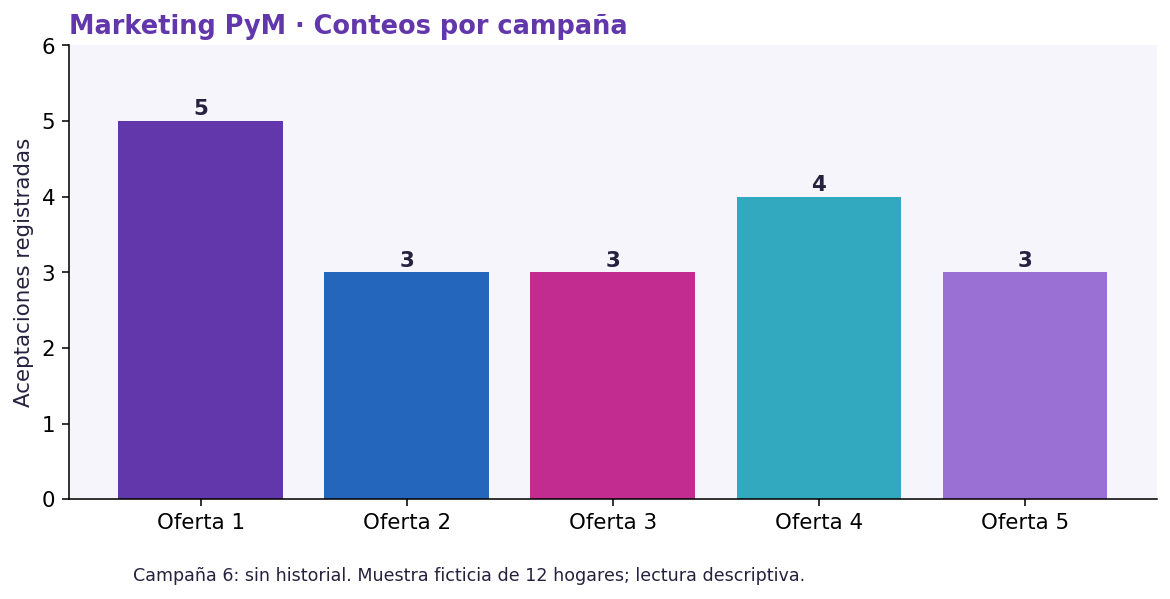

In [22]:
datos_grafico = marketing_campanas_sql[marketing_campanas_sql["Aceptaciones"].notna()].sort_values("CampanaID")
fig, ax = plt.subplots(figsize=(8.5, 4.3))
barras = ax.bar(datos_grafico["NombreCampana"], datos_grafico["Aceptaciones"], color=COLORES_PYM)
for barra in barras:
    altura = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2, altura + 0.08, f"{int(altura)}", ha="center", fontweight="bold")
ax.set_ylim(0, 6)
ax.set_ylabel("Aceptaciones registradas")
ax.set_title("Marketing PyM · Conteos por campaña", loc="left", fontweight="bold", color="#6337ac")
fig.text(0.12, 0.02, "Campaña 6: sin historial. Muestra ficticia de 12 hogares; lectura descriptiva.", fontsize=9)
fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()
plt.close(fig)


### La misma cobertura con `RIGHT JOIN` — recorrido complementario resuelto

También podemos conservar el catálogo a la derecha de un `RIGHT JOIN`. La intención
es observar la equivalencia de cobertura, no cambiar el significado del reporte.
El bloque revisa la versión de SQLite: cuando ese tipo de unión no está disponible,
conserva el resultado ya obtenido con `LEFT JOIN` y continúa sin instalar nada.


In [23]:
if sqlite3.sqlite_version_info >= (3, 39, 0):
    campanas_right = consultar("""
    SELECT c.CampanaID, c.NombreCampana, r.Aceptaciones
    FROM (
        SELECT CampanaID, SUM(Aceptada) AS Aceptaciones
        FROM respuestas_mk
        GROUP BY CampanaID
    ) AS r
    RIGHT JOIN cat_campanas AS c USING (CampanaID)
    ORDER BY r.Aceptaciones DESC, c.CampanaID ASC
    """)
    pd.testing.assert_frame_equal(campanas_right, marketing_campanas_sql, check_dtype=False)
    print("RIGHT JOIN y LEFT JOIN conservan las mismas seis campañas.")
else:
    campanas_right = marketing_campanas_sql.copy()
    print("Esta versión conserva el recorrido con LEFT JOIN, que tiene la misma cobertura.")
display(campanas_right)


RIGHT JOIN y LEFT JOIN conservan las mismas seis campañas.


,CampanaID,NombreCampana,Aceptaciones
0,1,Oferta 1,5.0
1,4,Oferta 4,4.0
2,2,Oferta 2,3.0
3,3,Oferta 3,3.0
4,5,Oferta 5,3.0
5,6,Oferta 6: sin historial,NaN


## 12. Preparar una entrega que otra persona pueda revisar

Guardamos la lista SQL, el resumen de campañas y dos controles de apoyo. Los CSV
llevan nombres que explican su contenido; `index=False` evita una columna artificial.
Al releer verificamos que el archivo que recibirá coordinación conserve los valores.

En el CSV de campañas el campo de la campaña 6 queda vacío porque no hay historial.
Su nombre y el mensaje de entrega explican ese estado; no lo rellenamos con cero.
La libreta conserva además la lista Python con `SegmentoGasto` para documentar la regla.


In [24]:
archivos_entrega = {
    "marketing_lista_sql.csv": marketing_lista_sql,
    "marketing_campanas_sql.csv": marketing_campanas_sql,
    "marketing_control_conteos.csv": control_sql,
    "marketing_auditoria_cruces.csv": auditoria_cruces
}
for nombre, tabla in archivos_entrega.items():
    ruta = carpeta_salida / nombre
    tabla.to_csv(ruta, index=False, encoding="utf-8-sig")
    recuperada = pd.read_csv(ruta, encoding="utf-8-sig")
    pd.testing.assert_frame_equal(tabla.reset_index(drop=True), recuperada, check_dtype=False)
    print("Archivo verificado:", ruta.name, "·", len(tabla), "filas")
print("Carpeta de entrega:", carpeta_salida)


Archivo verificado: marketing_lista_sql.csv · 5 filas
Archivo verificado: marketing_campanas_sql.csv · 6 filas
Archivo verificado: marketing_control_conteos.csv · 4 filas
Archivo verificado: marketing_auditoria_cruces.csv · 3 filas
Carpeta de entrega: /workspace/scratch/a72119b51a6b/work/run_marketing/pym_marketing/entregables


### Convertir el análisis en tres frases para coordinación

La persona que recibe el reporte necesita saber qué contiene, cómo interpretar sus
cifras y dónde termina su alcance. El mensaje siguiente se construye con los
resultados de la libreta para que la narrativa permanezca conectada a las tablas.
Aquí queda preparado junto con los entregables para acompañar la explicación.


In [25]:
mensaje_coordinacion = (
    f"De {len(df_bruto_mk)} filas recibidas quedaron {len(df_preparado_mk)} hogares únicos; "
    f"la lista preliminar contiene {len(marketing_lista_sql)} hogares con hijos, gasto acumulado "
    f"de al menos 600 UM y sin queja, que suman {gasto_lista_python:,.0f} UM. "
    f"Se registraron {total_aceptaciones_python} aceptaciones de {n_aceptantes_sql} hogares diferentes, "
    f"{n_sin_aceptaciones_sql} hogares sin aceptación y {n_quejas_python} con queja; "
    f"el gasto acumulado de todos los hogares aceptantes, contado una sola vez, es "
    f"{marketing_gasto_unico.loc[0, 'GastoAcumuladoUM']:,.0f} UM. "
    "La campaña 6 no tiene historial y estas cifras describen la muestra: sin datos de inversión, "
    "exposición ni ventas atribuibles no permiten concluir rentabilidad o efecto causal de las campañas."
)
display(Markdown("**Mensaje para coordinación:** " + mensaje_coordinacion))


**Mensaje para coordinación:** De 13 filas recibidas quedaron 12 hogares únicos; la lista preliminar contiene 5 hogares con hijos, gasto acumulado de al menos 600 UM y sin queja, que suman 3,800 UM. Se registraron 18 aceptaciones de 9 hogares diferentes, 3 hogares sin aceptación y 3 con queja; el gasto acumulado de todos los hogares aceptantes, contado una sola vez, es 7,000 UM. La campaña 6 no tiene historial y estas cifras describen la muestra: sin datos de inversión, exposición ni ventas atribuibles no permiten concluir rentabilidad o efecto causal de las campañas.

## 13. 🤖 Apoyarnos en IA con una revisión concreta

Podemos pedir ayuda para revisar una consulta cuando ya entendemos su propósito.
Este es un **prompt listo para reutilizar**, acompañado de la revisión resuelta:

> Actúa como revisor de SQL para un analista jr. `hogares_mk` tiene una fila por ID
> y seis categorías de gasto; `respuestas_mk` tiene una fila por ID–CampanaID y una
> bandera Aceptada. Necesito contar hogares con alguna aceptación y sumar su gasto
> acumulado una sola vez. Revisa una unión directa filtrada por Aceptada = 1:
> explica qué representa cada fila después del cruce y propón una corrección con
> subconsulta y DISTINCT sobre ID. No atribuyas el gasto a las campañas. Indica
> cómo contrastar conteos e importes con la base de hogares.

**Nuestra revisión resuelta:** la unión directa genera una fila por aceptación;
corregimos la llave antes de unir y comprobamos 9 hogares y 7,000 UM contra pandas.
Comparamos, además, con las 18 filas y 15,200 UM del cruce directo.

👀 El prompt es un recurso para una revisión futura; el ejemplo de validación está
resuelto con los datos de esta guía. Comprobamos el significado de una sugerencia
y sus resultados antes de incorporarla al reporte.


## 14. Uniendo las piezas: qué acabamos de hacer como analistas

| Paso del día de trabajo | Decisión y evidencia en esta guía |
|---|---|
| Entender el pedido | Separar lista preliminar, aceptaciones y hogares aceptantes. |
| Recibir y diagnosticar | Registrar 13 filas, detectar una carga repetida y revisar tipos/faltantes. |
| Preparar con Python | Conservar 12 hogares; crear gasto, hijos, canales y segmento acordado. |
| Consultar con SQL | Reproducir filtros; agrupar campañas; conservar su catálogo. |
| Auditar relaciones | Comparar la unión directa con una llave única por hogar. |
| Comunicar | Entregar CSV verificados y tres frases con cifras y límites. |

**El papel de marketing en el curso:** comenzar a explorar clientes en C3 nos llevó
a construir una lista útil, interpretar respuestas y controlar un problema real de
reportería: cambiar inadvertidamente la unidad de una fila al relacionar tablas.

**Para reutilizarlo en el siguiente corte:** se reemplaza el bloque del insumo,
se revisan las reglas y las llaves y se ejecuta la libreta desde el inicio. Los
controles deben seguir conciliando; los valores esperados de esta muestra se actualizan
cuando el nuevo corte tenga otros datos. Las funciones reutilizables y la consulta
quedan separadas de la explicación para que el proceso sea fácil de seguir.

🔥 El trabajo termina cuando la cifra se puede explicar y sostener: sabemos qué
hogares incluye, qué cuenta cada indicador y por qué el gasto no se multiplica.

**Base didáctica:** `Casos_de_uso_C3 (1).ipynb` (enfoque y continuidad),
`Copia_de_Tarea_2_intermedio_202610 (2)(1).ipynb` (consignas originales de Python) y
`Tarea_3_SQL_Contexto_Laboral_PyM.ipynb` (consultas, relaciones y controles).
Los datos son las mismas simulaciones docentes de las tareas, no registros empresariales reales.


In [26]:
# Cierre: confirmar que la preparación no alteró lo recibido.
pd.testing.assert_frame_equal(df_bruto_mk, original_recibido)
assert len(marketing_lista_sql) == 5 and len(marketing_campanas_sql) == 6
assert int(marketing_gasto_unico.loc[0, "Hogares"]) == 9
print("Recorrido completo: preparación, SQL, controles y entregables verificados.")


Recorrido completo: preparación, SQL, controles y entregables verificados.
